In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080206
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] None
[Conda 环境] None
[学号] 20244080206
[机器指纹] e0168deb8a9ab8df
[RUN_ID] 20244080206-e0168deb8a9ab8df


导入库

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False


一、半圆定律
1. 编写半圆密度函数

In [3]:
def wigner_density(x):
    """
    计算标准半圆分布密度。

    当 |x| <= 2 时：
        f(x) = sqrt(4 - x^2) / (2 * pi)

    当 |x| > 2 时：
        f(x) = 0
    """
    x = np.asarray(x)

    density = np.where(
        np.abs(x) <= 2,
        np.sqrt(np.maximum(0, 4 - x ** 2)) / (2 * np.pi),
        0.0
    )

    # 对单个输入返回 Python float
    if density.ndim == 0:
        return float(density)

    return density


测试函数：

In [4]:
test_values = [-3, -2, -1, 0, 1, 2, 3]

for value in test_values:
    print(f"wigner_density({value}) = {wigner_density(value)}")


wigner_density(-3) = 0.0
wigner_density(-2) = 0.0
wigner_density(-1) = 0.27566444771089604
wigner_density(0) = 0.3183098861837907
wigner_density(1) = 0.27566444771089604
wigner_density(2) = 0.0
wigner_density(3) = 0.0


2. 生成 Wigner 矩阵

In [5]:
def generate_wigner(n):
    """
    生成 n 阶 Wigner 对称随机矩阵。

    上三角元素独立服从 N(0, 1/n)，
    再通过对称化得到完整矩阵。
    """
    if not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")

    if n <= 0:
        raise ValueError("n 必须是正整数")

    # 先生成上三角矩阵
    upper = np.zeros((n, n), dtype=float)

    for i in range(n):
        for j in range(i, n):
            upper[i, j] = np.random.normal(
                loc=0.0,
                scale=1 / np.sqrt(n)
            )

    # 上三角 + 严格上三角的转置
    matrix = upper + np.triu(upper, k=1).T

    return matrix


测试矩阵：

In [6]:
np.random.seed(42)

test_matrix = generate_wigner(5)

print("生成的 Wigner 矩阵：")
print(test_matrix)

print("\n是否为对称矩阵：")
print(np.allclose(test_matrix, test_matrix.T))


生成的 Wigner 矩阵：
[[ 0.22213732 -0.06183368  0.28965512  0.68111966 -0.10471657]
 [-0.06183368 -0.10470923  0.70624544  0.34320724 -0.20995533]
 [ 0.28965512  0.70624544  0.24264023 -0.20724669 -0.20828068]
 [ 0.68111966  0.34320724 -0.20724669  0.10820882 -0.85564494]
 [-0.10471657 -0.20995533 -0.20828068 -0.85564494 -0.77140671]]

是否为对称矩阵：
True


3. 计算特征值

In [7]:
def get_spectrum(matrix):
    """
    返回矩阵的全部特征值，并按非递减顺序排列。
    """
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)


测试：

In [8]:
eigenvalues = get_spectrum(test_matrix)

print("特征值：")
print(eigenvalues)

print("\n特征值是否已经按非递减顺序排列：")
print(np.all(eigenvalues[:-1] <= eigenvalues[1:]))


特征值：
[-1.45372499e+00 -7.95642437e-01 -1.09219540e-03  6.84696179e-01
  1.26263387e+00]

特征值是否已经按非递减顺序排列：
True


4. 绘制四个不同阶数的特征值直方图

正在计算 n=100 的特征值，请稍候……
正在计算 n=200 的特征值，请稍候……
正在计算 n=500 的特征值，请稍候……
正在计算 n=1000 的特征值，请稍候……


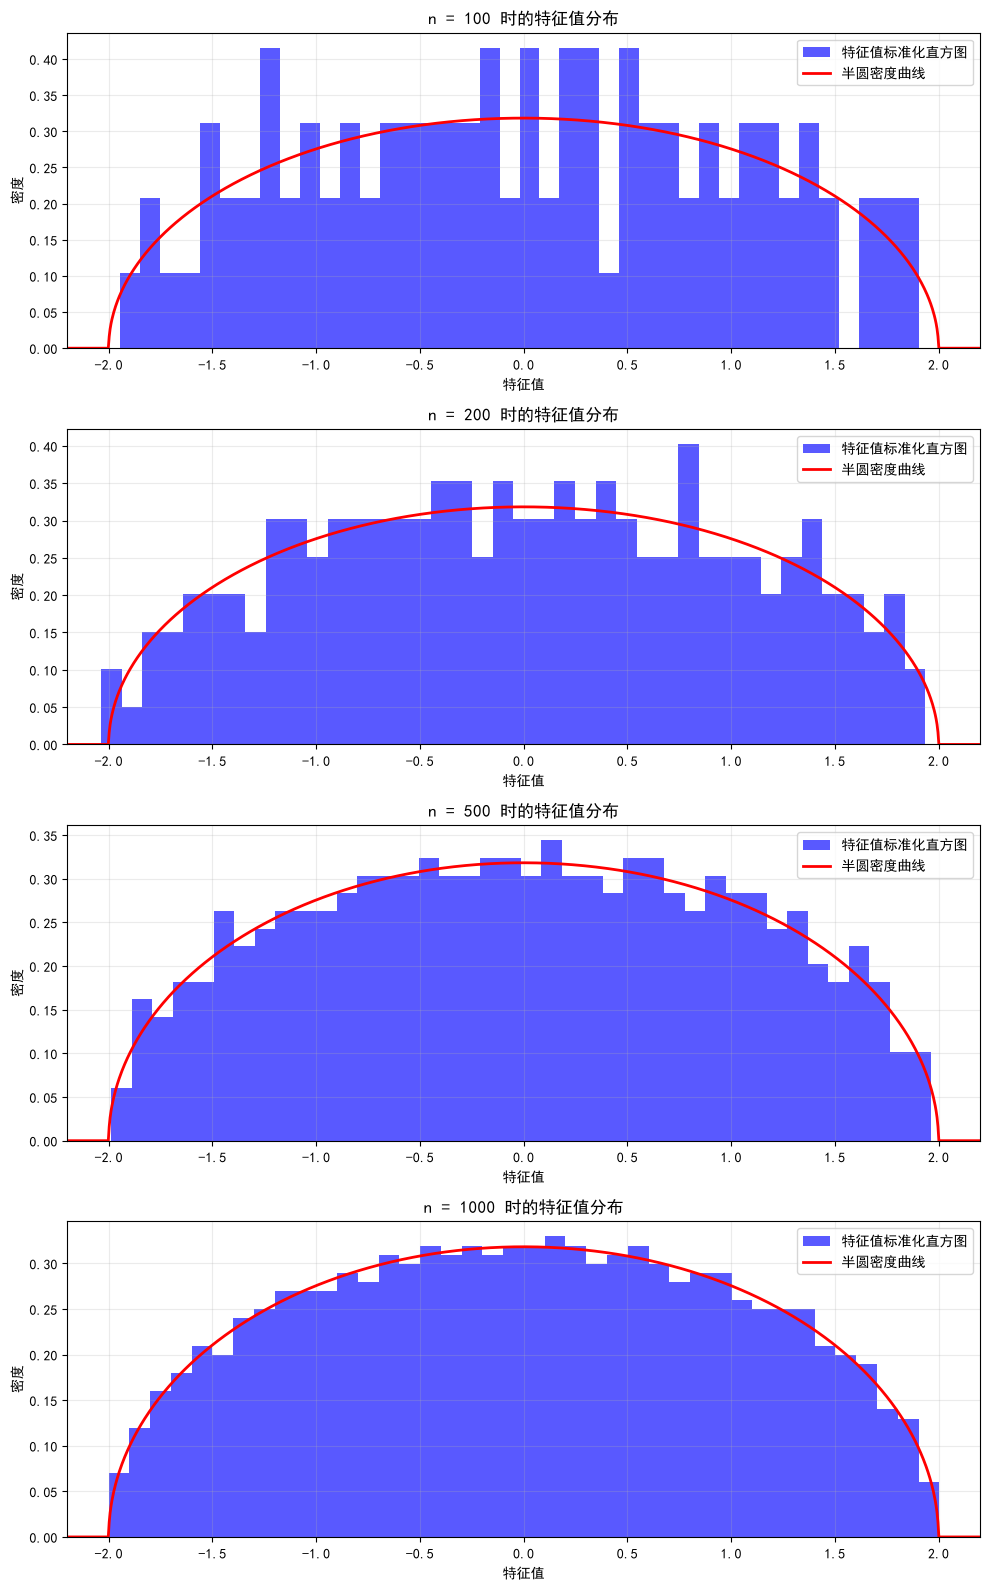

In [9]:
matrix_sizes = [100, 200, 500, 1000]

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(10, 16)
)

x_values = np.linspace(-2.2, 2.2, 1000)
density_values = wigner_density(x_values)

for ax, n in zip(axes, matrix_sizes):
    print(f"正在计算 n={n} 的特征值，请稍候……")

    matrix = generate_wigner(n)
    spectrum = get_spectrum(matrix)

    # density=True 表示直方图已经标准化
    ax.hist(
        spectrum,
        bins=40,
        density=True,
        color="blue",
        alpha=0.65,
        label="特征值标准化直方图"
    )

    ax.plot(
        x_values,
        density_values,
        color="red",
        linewidth=2,
        label="半圆密度曲线"
    )

    ax.set_title(f"n = {n} 时的特征值分布")
    ax.set_xlabel("特征值")
    ax.set_ylabel("密度")
    ax.set_xlim(-2.2, 2.2)
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


随着矩阵阶数 n 增大，特征值直方图逐渐接近红色的半圆密度曲线。
当 n 较小时，直方图受随机性的影响较明显，波动较大。
当 n 达到几百阶甚至更高时，特征值分布通常能够较好地拟合半圆定律。

二、Conway 生命游戏
1. 判断棋盘是否合法

In [10]:
def is_valid_board(board):
    """
    判断输入是否为有效的生命游戏棋盘。

    有效条件：
    1. 必须是 NumPy ndarray；
    2. 必须是二维数组；
    3. 元素只能是 0 或 1。
    """
    if not isinstance(board, np.ndarray):
        return False

    if board.ndim != 2:
        return False

    return bool(np.all(np.isin(board, [0, 1])))


测试：

In [11]:
valid_board = np.array([
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1]
])

invalid_board_1 = np.array([0, 1, 2])
invalid_board_2 = np.array([[0, 1], [1, 0.5]])

print("valid_board 是否有效：", is_valid_board(valid_board))
print("invalid_board_1 是否有效：", is_valid_board(invalid_board_1))
print("invalid_board_2 是否有效：", is_valid_board(invalid_board_2))


valid_board 是否有效： True
invalid_board_1 是否有效： False
invalid_board_2 是否有效： False


2. 计算生命游戏下一步状态

In [12]:
def gol_step(board):
    """
    根据 Conway 生命游戏规则计算下一步棋盘。
    棋盘采用环绕边界。
    """
    if not is_valid_board(board):
        raise ValueError("board 必须是二维 NumPy 数组，且元素只能为 0 或 1")

    board = board.astype(np.int8)
    neighbor_count = np.zeros_like(board, dtype=np.int8)

    # 八个邻居方向
    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    # 使用 np.roll 实现环绕边界
    for row_shift, col_shift in directions:
        neighbor_count += np.roll(
            np.roll(board, row_shift, axis=0),
            col_shift,
            axis=1
        )

    # 生命游戏规则：
    # 活细胞有 2 或 3 个邻居时存活
    # 死细胞有恰好 3 个邻居时复活
    next_board = (
        ((board == 1) & ((neighbor_count == 2) | (neighbor_count == 3))) |
        ((board == 0) & (neighbor_count == 3))
    ).astype(np.int8)

    return next_board


使用滑翔机测试：

In [13]:
glider = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
], dtype=np.int8)

print("初始棋盘：")
print(glider)

next_glider = gol_step(glider)

print("\n下一步棋盘：")
print(next_glider)


初始棋盘：
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

下一步棋盘：
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]


3. 绘制生命游戏棋盘

In [14]:
def draw_gol_board(board):
    """
    绘制生命游戏棋盘：
    活细胞为黑色，死细胞为白色。
    """
    if not is_valid_board(board):
        raise ValueError("board 必须是二维 NumPy 数组，且元素只能为 0 或 1")

    cmap = ListedColormap(["white", "black"])

    plt.figure(figsize=(6, 6))
    plt.imshow(
        board,
        cmap=cmap,
        interpolation="nearest",
        vmin=0,
        vmax=1
    )

    # 不显示网格线、轴标签和轴刻度
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel("")
    plt.ylabel("")
    plt.title("Conway 生命游戏棋盘")
    plt.show()


绘制测试：

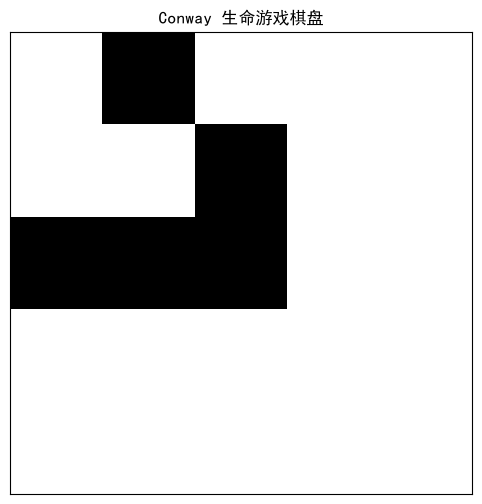

In [15]:
draw_gol_board(glider)

连续演化若干步：

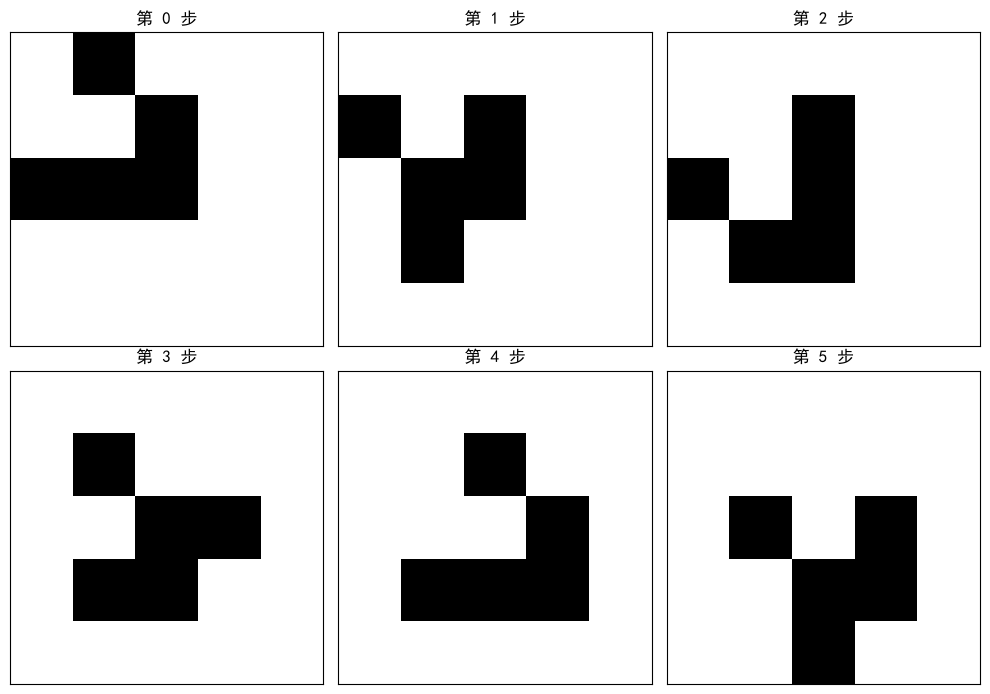

In [16]:
board = glider.copy()

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
cmap = ListedColormap(["white", "black"])

for step, ax in enumerate(axes.flat):
    ax.imshow(
        board,
        cmap=cmap,
        interpolation="nearest",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"第 {step} 步")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

    board = gol_step(board)

plt.tight_layout()
plt.show()


三、使用 pandas 处理 iris.csv
1. 读取数据

In [17]:
import pandas as pd
import numpy as np

# 读取 iris.csv
# 第一列 0, 1, 2, ... 是原始索引，不是测量数据
iris = pd.read_csv("iris.csv", index_col=0)

# 重置为连续的默认索引 0, 1, 2, ...
iris = iris.reset_index(drop=True)

print("数据集形状：")
print(iris.shape)

print("\n原始列名：")
print(iris.columns.tolist())

display(iris.head())


数据集形状：
(150, 4)

原始列名：
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


2. 补充并统一列名并检查数据集信息

In [18]:
iris["Species"] = np.select(
    [
        iris.index < 50,
        iris.index < 100
    ],
    [
        "setosa",
        "versicolor"
    ],
    default="virginica"
)

print("添加 Species 后的列名：")
print(iris.columns.tolist())

display(iris.head())
display(iris.tail())

#定义实际列名
sepal_length = "sepal length (cm)"
sepal_width = "sepal width (cm)"
petal_length = "petal length (cm)"
petal_width = "petal width (cm)"

measurement_columns = [
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
]

# 转换四个测量列的数据类型
for column in measurement_columns:
    iris[column] = pd.to_numeric(
        iris[column],
        errors="coerce"
    )


添加 Species 后的列名：
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


3. 修改第 35 行和第 38 行

In [19]:
# 修改第 35 个数据行
iris.loc[34, measurement_columns] = [
    4.9, 3.1, 1.5, 0.2
]
iris.loc[34, "Species"] = "setosa"

# 修改第 38 个数据行
iris.loc[37, measurement_columns] = [
    4.9, 3.6, 1.4, 0.1
]
iris.loc[37, "Species"] = "setosa"

print("修改后的第 35 个数据行：")
display(iris.loc[[34]])

print("修改后的第 38 个数据行：")
display(iris.loc[[37]])


修改后的第 35 个数据行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
34,4.9,3.1,1.5,0.2,setosa


修改后的第 38 个数据行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
37,4.9,3.6,1.4,0.1,setosa


4. 添加 Petal.Ratio 和 Sepal.Ratio

In [20]:
# 先确认当前列名
print(iris.columns.tolist())

# 使用 iris.csv 中的真实列名计算比例
iris["Petal.Ratio"] = (
    iris["petal length (cm)"] /
    iris["petal width (cm)"]
)

iris["Sepal.Ratio"] = (
    iris["sepal length (cm)"] /
    iris["sepal width (cm)"]
)

print("添加比例特征后的前五行：")
display(iris.head())


['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']
添加比例特征后的前五行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Petal.Ratio,Sepal.Ratio
0,5.1,3.5,1.4,0.2,setosa,7.0,1.457143
1,4.9,3.0,1.4,0.2,setosa,7.0,1.633333
2,4.7,3.2,1.3,0.2,setosa,6.5,1.468750
3,4.6,3.1,1.5,0.2,setosa,7.5,1.483871
4,5.0,3.6,1.4,0.2,setosa,7.0,1.388889


5.检查缺失值

In [21]:
print("各列缺失值数量：")
print(iris.isna().sum())

print("\n包含缺失值的行：")
display(iris[iris.isna().any(axis=1)])


各列缺失值数量：
sepal length (cm)    1
sepal width (cm)     1
petal length (cm)    0
petal width (cm)     0
Species              0
Petal.Ratio          0
Sepal.Ratio          2
dtype: int64

包含缺失值的行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Petal.Ratio,Sepal.Ratio
24,NaN,3.4,1.9,0.2,setosa,9.5000,NaN
56,6.3,NaN,4.7,1.6,versicolor,2.9375,NaN


6.按花卉种类分组统计

In [22]:
grouped_statistics = iris.groupby("Species")[
    ["Petal.Ratio", "Sepal.Ratio"]
].agg(
    ["mean", "median", "min", "max", "std"]
)

display(grouped_statistics)


Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
Species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992

7.保存修改后的数据

In [23]:
iris.to_csv(
    "iris_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

print("文件已保存为 iris_corrected.csv")


文件已保存为 iris_corrected.csv


8.修改错误并保存

In [24]:
# 修正明显错误的 petal width
iris.loc[50, "petal width (cm)"] = 1.4

# 重新计算两个比例特征
iris["Petal.Ratio"] = (
    iris["petal length (cm)"] /
    iris["petal width (cm)"]
)

iris["Sepal.Ratio"] = (
    iris["sepal length (cm)"] /
    iris["sepal width (cm)"]
)

# 检查第 35 行、第 38 行和异常数据行
print("第 35 个数据行：")
display(iris.loc[[34]])

print("第 38 个数据行：")
display(iris.loc[[37]])

print("修正后的索引 50 数据：")
display(iris.loc[[50]])

# 检查缺失值
print("各列缺失值数量：")
print(iris.isna().sum())

# 保存
iris.to_csv(
    "iris_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

print("保存 iris_corrected.csv")


第 35 个数据行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Petal.Ratio,Sepal.Ratio
34,4.9,3.1,1.5,0.2,setosa,7.5,1.580645


第 38 个数据行：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Petal.Ratio,Sepal.Ratio
37,4.9,3.6,1.4,0.1,setosa,14.0,1.361111


修正后的索引 50 数据：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Petal.Ratio,Sepal.Ratio
50,7.0,3.2,4.7,1.4,versicolor,3.357143,2.1875


各列缺失值数量：
sepal length (cm)    1
sepal width (cm)     1
petal length (cm)    0
petal width (cm)     0
Species              0
Petal.Ratio          0
Sepal.Ratio          2
dtype: int64
保存 iris_corrected.csv
